# 5. Curved effects: why older women were over-flagged

> **In plain terms.** The model over-flagged older women because it assumed risk keeps rising with age, when it actually peaks around 50. Letting age, glucose and BMI curve fixed much of this: 40 fewer false alarms overall, and twice as many healthy older women correctly cleared. It costs some missed cases among women under 30.

Every model so far assumed each input pushes risk along a straight line: each extra year of age adds the same amount. Milestone 2 left one open bug, B10: with one cut-off for everyone, the model clears only 22% of healthy women aged 45 and over. This notebook finds out why, tests nine ways of letting effects bend or interact (E10, E11), gives insulin one more hearing (E29), and ends by changing the published model.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 5.1 What the straight line gets wrong

**What we're looking for.** Whether the model's predicted risk matches the real diabetes rate at every age, not just on average.

In [2]:
from sklearn.metrics import roc_auc_score
from src.data import load_data, FEATURES
from src.modeling import current_features
from src.evaluate import out_of_fold, confusion_at, pick_threshold
from src import nonlinear as nl
from src import figures

X, y = load_data()
Xc = X[current_features(FEATURES)]                    # the six inputs from Milestone 2
p_straight = out_of_fold(nl.lr_pipeline(), Xc, y)     # the Milestone 2 model, held-out predictions
nl.calibration_by_age(X, y, p_straight)

,women,actual,predicted
Age,,,
21-24,219,0.142,0.201
25-29,177,0.299,0.295
30-34,92,0.457,0.371
35-39,73,0.466,0.449
40-44,74,0.568,0.489
45-49,44,0.523,0.481
50-54,35,0.714,0.593
55-59,22,0.409,0.521
60+,32,0.281,0.500


**How to read it.** Each row is a five-year age group. `actual` is the share of those women diagnosed with diabetes; `predicted` is the model's average risk for them, from predictions made without seeing them.

**What it means.** The real rate climbs from 14% at 21 to 24, to 71% at 50 to 54, then falls to 41% and 28%. A straight line can only keep climbing, so the model says about 50% for women 60 and over, who are really at 28%. It is also too high for the youngest group (20% against 14%) and too low in the thirties. The fall after 55 may partly be survivorship (women who would develop diabetes often already have it), and only 54 women are over 55, so it is a real pattern but a noisy one.

**What's next and why.** Before fixing the shape, check how much of B10 the shape explains, and how much comes from something else.

## 5.2 B10 is two problems, not one

**What we're looking for.** For each age band: how common diabetes is, how well the model separates cases inside the band, and how many healthy women are cleared, first with the shared cut-off, then with a cut-off chosen for that band alone.

In [3]:
shared_cut = pick_threshold(y, p_straight)
rows = []
for band, m in nl.age_band_masks(X).items():
    rows.append({
        "band": band, "women": int(m.sum()), "have diabetes": y[m].mean(),
        "AUC inside band": roc_auc_score(y[m], p_straight[m]),
        "cleared, shared cut-off": confusion_at(y[m].to_numpy(), p_straight[m], shared_cut)["specificity"],
        "cleared, band's own cut-off": nl.band_specificity(y, p_straight, m),
    })
print(f"Shared cut-off: {shared_cut:.2f}")
pd.DataFrame(rows).set_index("band")

Shared cut-off: 0.23


,women,have diabetes,AUC inside band,"cleared, shared cut-off","cleared, band's own cut-off"
band,,,,,
21 to 29,396,0.212,0.857,0.747,0.654
30 to 44,239,0.494,0.796,0.479,0.521
45 and over,133,0.496,0.744,0.224,0.388


**How to read it.** "Cleared" means healthy women correctly not flagged (specificity). The band's own cut-off is set so it still catches 85% of that band's cases, so the last column shows how well the model sorts women within the band, free of the base rate.

**What it means.** Half of women 45 and over have diabetes, against 21% under 30. A model that is right about that will give older women high risks, and a shared cut-off then flags most of them. That part of B10 is the base rate, not a fault. But even with its own cut-off the band clears only 39%, because the model separates older women less well (AUC 0.74 against 0.86 under 30). The wrong age shape from 5.1 is one likely cause of that weaker separation, and that part can be fixed.

**What's next and why.** Try models that let the effects bend, and see whether separation among older women improves.

## 5.3 Nine models on the same 50 splits

**What we're looking for.** Whether curves, interactions or boosted models beat the straight-line model overall and, above all, for women 45 and over.

- Straight lines (Milestone 2)
- Log scale for skewed inputs
- Curve for age only
- Curves for glucose, BMI and age
- Age x glucose interaction
- Curves + interaction
- Explainable Boosting Machine
- EBM with pairwise interactions
- Boosting, risk can only rise


,auc,auc_sd,brier,auc_45plus,spec_45plus
model,,,,,
"Curves for glucose, BMI and age",0.853,0.027,0.149,0.791,0.642
Curves + interaction,0.853,0.026,0.149,0.789,0.612
Curve for age only,0.847,0.025,0.151,0.786,0.522
Explainable Boosting Machine,0.841,0.026,0.154,0.772,0.493
EBM with pairwise interactions,0.840,0.027,0.154,0.773,0.507
Log scale for skewed inputs,0.838,0.028,0.156,0.748,0.403
Straight lines (Milestone 2),0.838,0.027,0.156,0.744,0.388
Age x glucose interaction,0.837,0.026,0.156,0.737,0.328
"Boosting, risk can only rise",0.832,0.027,0.160,0.759,0.537


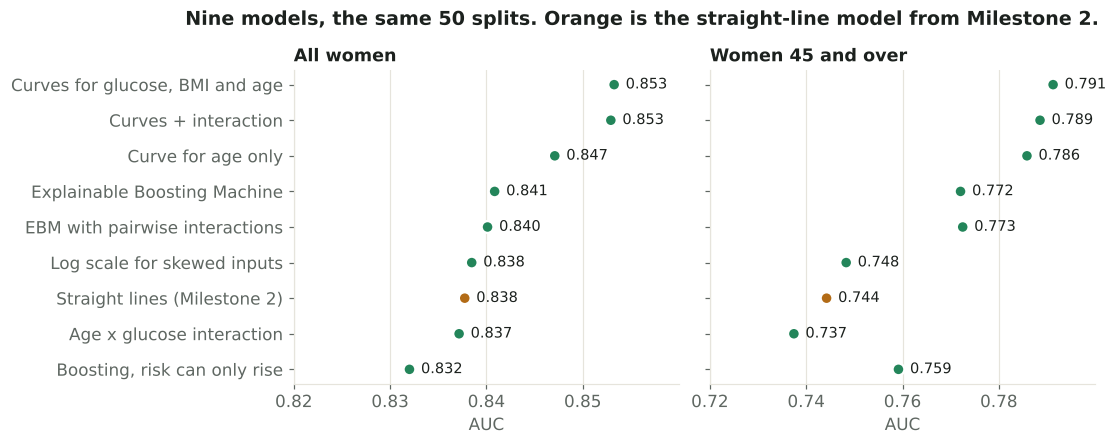

In [4]:
# Takes a few minutes: two of the models are Explainable Boosting Machines, fitted 50 times each.
for name in nl.candidates(Xc.columns):
    print("-", name)
table, probs = nl.compare(Xc, y)
display(table[["auc", "auc_sd", "brier", "auc_45plus", "spec_45plus"]].sort_values("auc", ascending=False))
figures.m3_models();

**How to read it.** Every model uses the same six inputs and the same 50 train/test splits. `auc` is overall; `auc_45plus` is the AUC among women 45 and over only; `spec_45plus` is the share of healthy older women cleared when that band's own cut-off catches 85% of its cases. "Curves" are splines: lines allowed to change slope at a few points. Extreme values are held at the 1st and 99th percentiles first, so a curve can't swing wildly where there are only a handful of women. The Explainable Boosting Machine (EBM) learns a curve per input by itself. The last model is gradient boosting forced so risk can only rise with glucose, BMI and family history.

**What it means.** Curves for glucose, BMI and age come out on top: AUC 0.853 against 0.838, and among women 45 and over 0.791 against 0.744, with 64% of healthy older women cleared instead of 39%. A curve for age alone gets most of the gain for older women (0.786). Adding the age-by-glucose interaction on top of the curves changes nothing, and log scales add nothing. The EBM finds similar shapes but scores lower (0.841), and the constrained boosting model is the weakest (0.832). With 768 women, a few well-chosen curves beat a model that has to discover every shape itself.

**What's next and why.** Nine candidates were tried and the best was picked, which flatters the winner slightly. Check the result split by split, then on a completely fresh set of splits.

## 5.4 Does the gain survive a second look?

**What we're looking for.** Whether the winner beats the straight line consistently, and whether the ranking holds on 50 new splits the models were never compared on.

In [5]:
display(table[["auc_vs_baseline", "wins"]].sort_values("auc_vs_baseline", ascending=False))

from sklearn.model_selection import RepeatedStratifiedKFold
fresh = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=2026)
check, _ = nl.compare(Xc, y, names=[nl.BASELINE, "Curve for age only", nl.CURVES], cv=fresh)
check[["auc", "auc_vs_baseline", "wins", "auc_45plus", "spec_45plus"]]

,auc_vs_baseline,wins
model,,
"Curves for glucose, BMI and age",0.016,0.860
Curves + interaction,0.015,0.860
Curve for age only,0.009,0.820
Explainable Boosting Machine,0.003,0.620
EBM with pairwise interactions,0.002,0.560
Log scale for skewed inputs,0.001,0.460
Straight lines (Milestone 2),0.000,0.000
Age x glucose interaction,-0.001,0.460
"Boosting, risk can only rise",-0.006,0.480


,auc,auc_vs_baseline,wins,auc_45plus,spec_45plus
model,,,,,
Straight lines (Milestone 2),0.840,0.000,0.000,0.745,0.358
Curve for age only,0.848,0.008,0.760,0.785,0.552
"Curves for glucose, BMI and age",0.854,0.014,0.780,0.791,0.627


**How to read it.** `auc_vs_baseline` is the average gain over the straight-line model on identical splits; `wins` is the share of the 50 splits where the model scored higher. The second table repeats the top three on a different random set of splits (seed 2026 instead of 42).

**What it means.** The curves model beats the straight line on 86% of splits, by 0.016 on average. On the fresh splits the order is the same and the gain is 0.014, winning 78% of the time. The gain is small but consistent, and it is concentrated where B10 lives: the 45-and-over AUC rises from 0.745 to 0.791 on the fresh splits too.

**What's next and why.** Look at the shapes the curves model learned, to check they make sense.

## 5.5 What the curves look like

**What we're looking for.** Whether each learned curve is believable, not just whether it scores well.

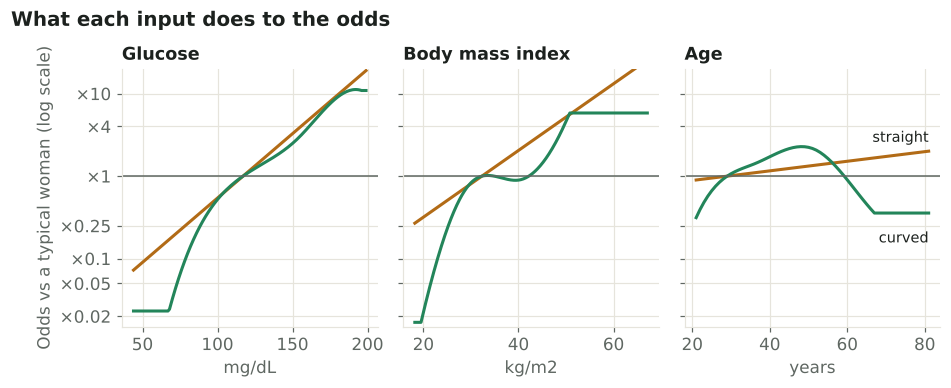

In [6]:
figures.shapes();

**How to read it.** Each panel shows how one input changes the odds of diabetes compared with a typical woman (who has the middle value of every measurement). Orange is the straight-line model, green the curved one. The vertical scale is logarithmic, so ×2 and ×0.5 are the same distance from ×1.

**What it means.** Glucose stays close to the straight line over the range where most women are (80 to 180 mg/dL), so bending it changes little. BMI climbs steeply up to about 30, is roughly flat from 30 to about 42, then climbs again; the flat stretch may be noise and is worth revisiting in Milestone 6. Age is the real change: odds rise to a peak near 50 and then turn down, where the straight line keeps rising. That matches the rates in 5.1, so the curve is following the data. The flat ends are the clipping at work, beyond the 1st and 99th percentiles.

**What's next and why.** Measure what the new shape does to B10 and to the screening numbers as a whole.

## 5.6 B10 before and after

**What we're looking for.** The screening results with one shared cut-off, the setting B10 was found in, for both models. Each cut-off is re-chosen so that 85% of all cases are caught.

,Straight lines (Milestone 2),Curves (Milestone 3)
cut-off,0.230,0.280
cases caught,231.000,229.000
missed,37.000,39.000
false alarms,194.000,154.000
healthy women 45+ cleared,0.224,0.433


Gain in older women cleared (own cut-off), 95% interval: -0.08 to +0.45


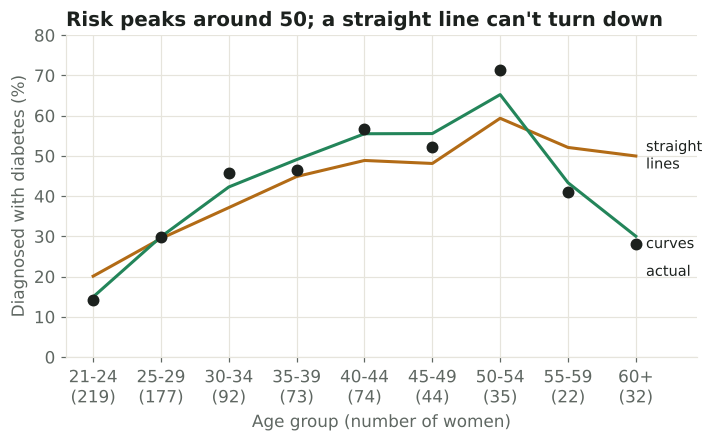

In [7]:
p_curves = probs[nl.CURVES]
older = (X["Age"] >= 45).to_numpy()
rows = {}
for name, p in [("Straight lines (Milestone 2)", p_straight), ("Curves (Milestone 3)", p_curves)]:
    cut = pick_threshold(y, p)
    every, old = confusion_at(y, p, cut), confusion_at(y[older].to_numpy(), p[older], cut)
    rows[name] = {"cut-off": cut, "cases caught": every["tp"], "missed": every["fn"],
                  "false alarms": every["fp"], "healthy women 45+ cleared": old["specificity"]}
display(pd.DataFrame(rows))
lo, hi = nl.bootstrap_band_gain(y, p_curves, p_straight, older)
print(f"Gain in older women cleared (own cut-off), 95% interval: {lo:+.2f} to {hi:+.2f}")
figures.age_fit();

**How to read it.** Both models are scored on held-out predictions. The interval comes from resampling the 133 older women 1,000 times. The chart compares the real rate in each age group (dots) with each model's average prediction (lines).

**What it means.** At the same 85% catch rate, false alarms fall from 194 to 154, and the share of healthy women 45 and over who are cleared nearly doubles, from 22% to 43%. The price is 2 more missed cases overall (39 against 37). The interval is wide, from slightly worse to much better, because only 67 healthy older women are in the data; the direction is clear, the size less so. The chart shows why: the green line follows the dots down after 55, the orange line does not.

**What's next and why.** Check who pays for the gain. A higher cut-off and lower risks for young women could cost something in the youngest band.

## 5.7 Who pays for it?

**What we're looking for.** Cases caught and missed in each age band, for both models at their shared cut-offs.

In [8]:
rows = []
for name, p in [("straight", p_straight), ("curves", p_curves)]:
    cut = pick_threshold(y, p)
    for band, m in nl.age_band_masks(X).items():
        c = confusion_at(y[m].to_numpy(), p[m], cut)
        rows.append({"model": name, "band": band, "caught": c["tp"], "missed": c["fn"],
                     "false alarms": c["fp"], "sensitivity": c["sensitivity"]})
pd.DataFrame(rows).pivot(index="band", columns="model", values=["caught", "missed", "false alarms", "sensitivity"])

caught          missed          false alarms           \
model        curves straight curves straight       curves straight   
band                                                                 
21 to 29     60.000   67.000 24.000   17.000       56.000   79.000   
30 to 44    110.000  104.000  8.000   14.000       60.000   63.000   
45 and over  59.000   60.000  7.000    6.000       38.000   52.000   

            sensitivity           
model            curves straight  
band                              
21 to 29          0.714    0.798  
30 to 44          0.932    0.881  
45 and over       0.894    0.909

**How to read it.** The same two models and cut-offs as 5.6, broken down by age band. Sensitivity is the share of each band's cases that are caught.

**What it means.** The gain is not free for everyone. Under 30, the curved model catches 60 of 84 cases against 67, so sensitivity falls from 80% to 71%, while 23 fewer young women get false alarms. In the 30s and early 40s it catches 6 more. This happens because the curved model gives young women lower, more accurate risks, and one shared cut-off then lets more young cases through. It is a cut-off problem, not a ranking problem: the AUC inside the youngest band is unchanged (0.85). Logged as B12.

**What's next and why.** One cut-off for everyone is a policy choice, and Milestone 5 is where cut-offs are set from costs. Band-specific cut-offs are added there as E31. First, insulin's second hearing.

## 5.8 Insulin's second hearing (E29)

**What we're looking for.** Whether insulin adds anything in the forms where it should matter most, tested only on the 394 women who have a real reading.

In [9]:
nl.insulin_retest(X, y)

,women,auc,auc_sd,auc_vs_six,wins
variant,,,,,
Six inputs (current),394,0.851,0.043,0.000,0.000
+ insulin,394,0.849,0.043,-0.003,0.260
+ log insulin,394,0.848,0.044,-0.003,0.300
+ log(glucose x insulin),394,0.848,0.044,-0.003,0.280


**How to read it.** Four versions of the straight-line model, all on the same 50 splits of those 394 women: the six current inputs, then the same plus raw insulin, log insulin, or the log of glucose times insulin, a rough measure of insulin resistance. `wins` is the share of splits where the version beat the six-input model.

**What it means.** None helps. All three lose 0.003 of AUC on average and win only about a quarter of the splits. Even where insulin was measured, it carries nothing that glucose and BMI don't already provide. Decision D09, leaving it out, stands.

**What's next and why.** Put it together and decide what the page should run.

## 5.9 Decision: publish the curves model

**What we're looking for.** The full set of results for the curved model next to the Milestone 2 model, and its export for the web page.

In [10]:
from src.evaluate import summarise

def row(s):
    t, d = s["threshold_screening"], s["threshold_default"]
    return {"AUC": s["oof_auc"], "cut-off": t["threshold"], "cases caught": t["tp"], "missed": t["fn"],
            "false alarms": t["fp"], "caught at 0.50": d["sensitivity"],
            "calibration slope": s["calibration"]["slope"], "cleared, age 45+": s["by_age"][2]["specificity"]}

before, after = summarise(Xc, y, p_straight), summarise(Xc, y, out_of_fold(nl.curves_model(), Xc, y))
display(pd.DataFrame([row(before), row(after)], index=["Milestone 2 (straight)", "Milestone 3 (curves)"]).T)

export = nl.export_curves_model(Xc, y)
check = nl.predict_from_export(export, export["check"]["inputs"])
print("Web page arithmetic vs scikit-learn, largest difference:", abs(check - export["check"]["probabilities"]).max())

,Milestone 2 (straight),Milestone 3 (curves)
AUC,0.838,0.854
cut-off,0.230,0.280
cases caught,231.000,229.000
missed,37.000,39.000
false alarms,194.000,154.000
caught at 0.50,0.556,0.612
calibration slope,0.971,0.945
"cleared, age 45+",0.224,0.433


Web page arithmetic vs scikit-learn, largest difference: 7.396367218692745e-08


**How to read it.** Each column is one model, scored on predictions for women it had not seen. The last line checks the web page's version of the model: it stores each input's curve as a lookup table and adds up the contributions, and that sum must match scikit-learn.

**What it means.** The curved model is better on almost every line: AUC 0.854 against 0.838, 40 fewer false alarms for 2 more missed cases, and calibration still close to ideal (slope 0.94). Decision D11: the page now runs it. B10 is closed as improved: 43% of healthy older women are now cleared instead of 22%, and the rest is mostly the base rate and a data limit. The trade-off for young women is open as B12. Because the model is a sum of one curve per input, the page can still show exactly what each measurement contributes.

**What's next and why.** Milestone 4 gives every model type a fair, tuned contest with nested cross-validation, now with the curves model as the one to beat.